# 01 — Análise Exploratória de Dados (EDA) e Engenharia de Atributos

**Competição:** IEEE-CIS Fraud Detection (Vesta Corporation)  
**Bases de Dados:** `train_transaction.csv` (Transações) + `train_identity.csv` (Identidade Digital e Dispositivos)  
**Objetivo deste Caderno:** Compreender a dinâmica operacional da fraude online, construir variáveis de domínio de alto sinal preditivo, tratar assimetrias e multicolinearidade, e exportar a tabela consolidada (`df_master.parquet`) pronta para a etapa de modelagem.

---

## Sumário

| Seção | Etapa do Pipeline | Conteúdo Principal |
|:---:|---|---|
| **[1.0](#10-configuração-inicial-e-coleta-de-dados)** | Configuração Inicial e Coleta de Dados | Imports, conexão com `utils.py`, autenticação Kaggle e leitura dos CSVs brutos |
| **[2.0](#20-visão-geral-das-bases-e-do-alvo-target)** | Visão Geral das Bases e do Alvo (Target) | Estrutura dimensional (`info`, `head`) e diagnóstico de desbalanceamento de `isFraud` (3,5%) |
| **[3.0](#30-raio-x-e-feature-engineering-transações-df_train_tr)** | Raio-X e Feature Engineering: Transações (`df_train_tr`) | Faixas de nulos, variáveis temporais/financeiras, domínios de e-mail, Bloco M, Cartões e anomalias do Bloco V |
| **[4.0](#40-painel-de-comportamento-da-fraude-visualizações-analíticas)** | Painel de Comportamento da Fraude | Sazonalidade horária, distribuição logarítmica de valores, risco por canal (`ProductCD`) e Concept Drift temporal |
| **[5.0](#50-raio-x-e-feature-engineering-identidade-df_train_id)** | Raio-X e Feature Engineering: Identidade (`df_train_id`) | Ranking de nulos, expurgo do bloco esparso (>90%), cardinalidade e engenharia de dispositivos/segurança |
| **[6.0](#60-unificação-merge-e-saneamento-financeiro)** | Unificação (Merge) e Saneamento Financeiro | `safe_downcast`, `left join` por `TransactionID`, desvios de gasto por cartão, Frequency Encoding e transformação `log1p` |
| **[7.0](#70-seleção-multivariada-e-exportação-o-funil-do-df_master)** | Seleção Multivariada e Exportação (`df_master`) | Information Value (IV), Funil de Saneamento (poda de ruído e correlação > 0.75), validação final de VIF e exportação Parquet/JSON |

---
## 1.0 Configuração Inicial e Coleta de Dados

Configuração do ambiente, importação das funções modulares do arquivo `utils.py` e coleta das bases brutas da competição **IEEE-CIS Fraud Detection** via `kagglehub`.

In [3]:
#KGAT_8ed74bf4c9839e81670ec5aa0603964e

#!pip install -r requirements.txt

In [4]:
import os
import sys
import json

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Garante que o módulo utils.py seja encontrado na raiz do projeto
sys.path.append(os.path.abspath(".."))
sys.path.append(os.path.abspath("."))

import utils
from utils import (
    plot_target_distribution,
    analisar_tipos_colunas,
    analisar_valores_nulos,
    analisar_nulos_por_faixa,
    analisar_valores_unicos,
    analisar_baixa_cardinalidade,
    safe_downcast,
    analise_correlacao_pares,
    analise_correlação_pares,
    analisar_e_transformar_caudas_longas,
    calcular_iv_dataset,
    analisar_vif,
)

In [5]:
DIR_ARQ = os.path.join(os.getcwd(), "data", "raw")
os.makedirs(DIR_ARQ, exist_ok=True)

In [6]:
kagglehub.login()

In [7]:
path = kagglehub.competition_download(
    "ieee-fraud-detection",
    force_download=True,
    output_dir=DIR_ARQ,
)

print("Path to competition files:", path)

100%|██████████| 118M/118M [00:06<00:00, 18.6MB/s] 

Extracting files...


Path to competition files: /content/data/raw


In [8]:
df_train_id = pd.read_csv(os.path.join(DIR_ARQ, "train_identity.csv"))
df_train_tr = pd.read_csv(os.path.join(DIR_ARQ, "train_transaction.csv"))

---
## 2.0 Visão Geral das Bases e do Alvo (Target)

Inspeção inicial da volumetria, consumo de memória, tipos primitivos e primeiras observações de `df_train_tr` (transações financeiras) e `df_train_id` (telemetria digital e identidade), seguida pela análise da variável resposta `isFraud`.

### 2.1 — Estrutura Dimensional e Amostra dos Dados (`info` e `head`)

In [9]:
df_train_tr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 590540 entries, 0 to 590539
Columns: 394 entries, TransactionID to V339
dtypes: float64(376), int64(4), object(14)
memory usage: 1.7+ GB


>
> **Veja que o dataset train_tr é enorme, possui 590k dados e 394 colunas**
>

In [10]:
df_train_tr.head(20)

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.500,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.000,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.000,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.000,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.000,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,2987005,0,86510,49.000,W,5937,555.0,150.0,visa,226.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2987006,0,86522,159.000,W,12308,360.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2987007,0,86529,422.500,W,12695,490.0,150.0,visa,226.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2987008,0,86535,15.000,H,2803,100.0,150.0,visa,226.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,2987009,0,86536,117.000,W,17399,111.0,150.0,mastercard,224.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
df_train_id.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144233 entries, 0 to 144232
Data columns (total 41 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   TransactionID  144233 non-null  int64  
 1   id_01          144233 non-null  float64
 2   id_02          140872 non-null  float64
 3   id_03          66324 non-null   float64
 4   id_04          66324 non-null   float64
 5   id_05          136865 non-null  float64
 6   id_06          136865 non-null  float64
 7   id_07          5155 non-null    float64
 8   id_08          5155 non-null    float64
 9   id_09          74926 non-null   float64
 10  id_10          74926 non-null   float64
 11  id_11          140978 non-null  float64
 12  id_12          144233 non-null  object 
 13  id_13          127320 non-null  float64
 14  id_14          80044 non-null   float64
 15  id_15          140985 non-null  object 
 16  id_16          129340 non-null  object 
 17  id_17          139369 non-nul

>
> **Veja que o dataset train_id não possui o target, tem 41 colunas e uma delas `TransactionID` é a coluna que usaremos para fazer o merge**
> 
> **Possui 144k linhas, bem menor que o `train_tr`**

In [12]:
df_train_id.head(20)

,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS
5,2987017,-5.0,61141.0,3.0,0.0,3.0,0.0,NaN,NaN,3.0,...,chrome 62.0,24.0,1366x768,match_status:2,T,F,T,T,desktop,Windows
6,2987022,-15.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2987038,0.0,31964.0,0.0,0.0,0.0,-10.0,NaN,NaN,0.0,...,chrome 62.0,32.0,1920x1080,match_status:2,T,F,T,T,mobile,NaN
8,2987040,-10.0,116098.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
9,2987048,-5.0,257037.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows


> **Interessante notar que muitas colunas possuem T,F ( valores que poderiam sofrer ordinal enconding pra ser transformadas em 0 e 1, preservando os valores nulos como uma flag de ausência de informação ).**
>

### 2.2 — Tipagem de Variáveis e Distribuição do Target (`isFraud`)

In [13]:
# Contagem de colunas numéricas e categóricas em df_train_tr
resumo_tipos_tr = analisar_tipos_colunas(df_train_tr, nome_df="df_train_tr")

--- Contagem de Colunas por Tipo (df_train_tr) ---
  Colunas numéricas inteiras : 4
  Colunas numéricas float    : 376
  Total de colunas numéricas : 380
  Colunas categóricas        : 14
  Total geral de colunas     : 394


--- Distribuição do Target (isFraud) ---
  isFraud=0 (Legítima / Adimplente):    569,877  (96.501%)
  isFraud=1 (Fraude / Default):          20,663  (3.499%)
  Valores nulos no target:                        0
  Ratio (0:1):                                 27.6:1



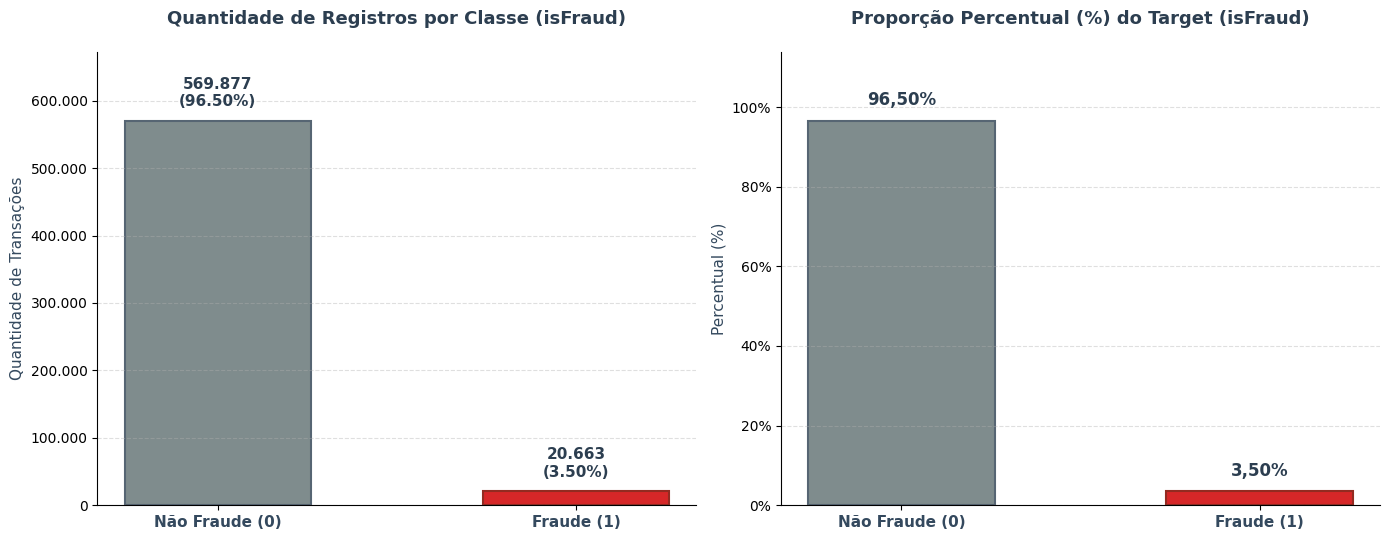

In [14]:
# Distribuição da classe alvo isFraud (Quantidade Absoluta e Proporção %)
target_counts, target_pct, ratio = plot_target_distribution(df_train_tr, target_col="isFraud")

>
> **3,5% de target: a classe é desbalanceada e precisam ser adotadas estratégias de balanceamento/pesos**
>
> **Há poucas colunas categóricas, vamos analisá-las junto aos nulos e cardinalidade**
>

---
## 3.0 Raio-X e Feature Engineering: Transações (`df_train_tr`)

Diagnóstico estrutural da tabela de transações e construção de atributos derivados de domínio financeiro e cadastral:
1. **3.1** — Agrupamento de Valores Nulos em Faixas (bins de 5%) e Análise de Cardinalidade
2. **3.2** — Feature Engineering: Variáveis Temporais e Financeiras (`Transaction_Hour`, `Transaction_Day`, `Transaction_DayOfWeek`, `TransactionAmt_Cents`)
3. **3.3** — Feature Engineering: Domínios de E-mail e Flags de Presença (`same_email_domain`, `P_email_suffix`, `tr_null_count`)
4. **3.4** — Feature Engineering: Bloco M, Cartões e Anomalias do Bloco V

### 3.1 — Agrupamento de Nulos em Faixas (5%) e Cardinalidade

In [15]:
# Agrupamento de nulos em 20 faixas de 5% (0% a 100%) via utils.py
analise_bins_tr = analisar_nulos_por_faixa(df_train_tr, n_faixas=20)
display(analise_bins_tr)

,faixa_nulos,qtd_colunas,exemplos,pct_do_total_colunas
0,"(-0.001, 5.0]",112,"TransactionID, isFraud, TransactionDT",28.43
1,"(5.0, 10.0]",0,,0.00
2,"(10.0, 15.0]",48,"addr1, addr2, D10",12.18
3,"(15.0, 20.0]",22,"P_emaildomain, D15, V75",5.58
4,"(20.0, 25.0]",0,,0.00
5,"(25.0, 30.0]",20,"D4, M6, V35",5.08
6,"(30.0, 35.0]",0,,0.00
7,"(35.0, 40.0]",0,,0.00
8,"(40.0, 45.0]",1,D3,0.25
9,"(45.0, 50.0]",17,"D2, D11, M1",4.31


In [16]:
# Tabela detalhada das Top 20 variáveis com mais nulos em df_train_tr
df_nulos_tr = analisar_valores_nulos(df_train_tr, plotar=False, top_n=20)
display(df_nulos_tr.head(20))

,Total Nulos,Percentual (%),Tipo de Dado
dist2,552913,93.63,float64
D7,551623,93.41,float64
D13,528588,89.51,float64
D14,528353,89.47,float64
D12,525823,89.04,float64
D6,517353,87.61,float64
D8,515614,87.31,float64
D9,515614,87.31,float64
V156,508595,86.12,float64
V139,508595,86.12,float64


In [17]:
# Valores únicos por coluna (menor cardinalidade primeiro)
df_unicos_tr = analisar_valores_unicos(df_train_tr, top_n=35)

,coluna,valores_unicos
0,isFraud,2
1,M1,3
2,M3,3
3,M2,3
4,M7,3
5,M6,3
6,M8,3
7,M5,3
8,V1,3
9,V107,3


In [18]:
# Distribuição percentual das colunas com até 5 valores únicos
colunas_baixa_card_tr = analisar_baixa_cardinalidade(df_train_tr, df_unicos=df_unicos_tr, max_unicos=5)

Total de colunas com cardinalidade <= 5: 33

--- Distribuição da coluna: isFraud ---
isFraud
0    96.5
1     3.5

--- Distribuição da coluna: M1 ---
M1
T      54.09
NaN    45.91
F       0.00

--- Distribuição da coluna: M3 ---
M3
NaN    45.91
T      42.63
F      11.47

--- Distribuição da coluna: M2 ---
M2
T      48.34
NaN    45.91
F       5.75

--- Distribuição da coluna: M7 ---
M7
NaN    58.64
F      35.79
T       5.57

--- Distribuição da coluna: M6 ---
M6
F      38.58
T      32.74
NaN    28.68

--- Distribuição da coluna: M8 ---
M8
NaN    58.63
F      26.29
T      15.08

--- Distribuição da coluna: M5 ---
M5
NaN    59.35
F      22.44
T      18.22

--- Distribuição da coluna: V1 ---
V1
1.0    52.70
NaN    47.29
0.0     0.00

--- Distribuição da coluna: V107 ---
V107
1.0    99.90
NaN     0.05
0.0     0.04

--- Distribuição da coluna: V14 ---
V14
1.0    87.07
NaN    12.88
0.0     0.04

--- Distribuição da coluna: V41 ---
V41
1.0    71.34
NaN    28.61
0.0     0.05

--- Distribuição da 

### 3.2 — Feature Engineering: Variáveis Temporais e Financeiras

In [19]:
# 1. Variáveis Temporais (TransactionDT em segundos convertido para Hora do Dia, Dia da Semana e Dias Corridos)
# O dataset cobre ~6 meses; a hora do dia isola ataques automatizados na madrugada
df_train_tr['Transaction_Hour'] = ((df_train_tr['TransactionDT'] // 3600) % 24).astype('int8')
df_train_tr['Transaction_DayOfWeek'] = ((df_train_tr['TransactionDT'] // (3600 * 24)) % 7).astype('int8')
df_train_tr['Transaction_Day'] = (df_train_tr['TransactionDT'] // (3600 * 24)).astype('int16')

# 2. Análise de Centavos (Parte Fracionária do Valor Transacionado)
# Compras locais têm centavos padronizados (.00, .99); fraudes internacionais/cambiais geram dízimas quebradas
df_train_tr['TransactionAmt_Cents'] = np.modf(df_train_tr['TransactionAmt'])[0].astype('float32')

print("Features temporais e financeiras criadas: Transaction_Hour, Transaction_DayOfWeek, Transaction_Day, TransactionAmt_Cents")

Features temporais e financeiras criadas: Transaction_Hour, Transaction_DayOfWeek, Transaction_Day, TransactionAmt_Cents


### 3.3 — Feature Engineering: Domínios de E-mail e Flags de Presença

In [20]:
# 1. Engenharia de Domínios de E-mail (Comprador P_emaildomain vs. Recebedor R_emaildomain)
# Flag indicando se comprador e destinatário utilizam exatamente o mesmo provedor de e-mail
df_train_tr['same_email_domain'] = (
    (df_train_tr['P_emaildomain'] == df_train_tr['R_emaildomain']) & 
    df_train_tr['P_emaildomain'].notnull()
).astype('int8')

# Extrai o sufixo de topo (.com, .net, .mx, etc.) que isola origens geográficas/provedores de risco
df_train_tr['P_email_suffix'] = df_train_tr['P_emaildomain'].str.split('.').str[-1]

# 2. Contagem Global de Nulos por Transação e Flags de Presença
cols_tr_features = [c for c in df_train_tr.columns if c not in ['TransactionID', 'isFraud']]
df_train_tr['tr_null_count'] = df_train_tr[cols_tr_features].isnull().sum(axis=1).astype('int16')
df_train_tr['has_dist2'] = df_train_tr['dist2'].notnull().astype('int8')
df_train_tr['has_R_email'] = df_train_tr['R_emaildomain'].notnull().astype('int8')

print("Features de e-mail e presença criadas: same_email_domain, P_email_suffix, tr_null_count, has_dist2, has_R_email")

Features de e-mail e presença criadas: same_email_domain, P_email_suffix, tr_null_count, has_dist2, has_R_email


### 3.4 — Feature Engineering: Bloco M, Cartões e Anomalias do Bloco V

In [21]:
# ==============================================================================
# 1. BLOCO M: FLAGS DE VALIDAÇÃO DE CADASTRO (M1 a M9)
# ==============================================================================
cols_m_bool = ['M1', 'M2', 'M3', 'M5', 'M6', 'M7', 'M8', 'M9']

# 1.1 Contagem de correspondências bem-sucedidas ('T') e falhas ('F')
# Compradores legítimos acumulam mais 'T'; fraudadores concentram mais 'F' ou NaNs
df_train_tr['M_true_count'] = (df_train_tr[cols_m_bool] == 'T').sum(axis=1).astype('int8')
df_train_tr['M_false_count'] = (df_train_tr[cols_m_bool] == 'F').sum(axis=1).astype('int8')

# 1.2 Assinatura conjunta do primeiro bloco de checkout (M1, M2, M3)
df_train_tr['M1_M2_M3_assinatura'] = (
    df_train_tr['M1'].fillna('X') + '_' +
    df_train_tr['M2'].fillna('X') + '_' +
    df_train_tr['M3'].fillna('X')
)

# 1.3 M4 tratado como categoria explícita (preservando NaN como 'Missing')
df_train_tr['M4_limpo'] = df_train_tr['M4'].fillna('Missing').astype('category')


# ==============================================================================
# 2. COMBINAÇÃO E LIMPEZA DE CARTÃO (card4 e card6)
# ==============================================================================
# 2.1 Agrupamento de categorias ultra-raras em card6 para evitar split quebrado no CV
df_train_tr['card6_limpo'] = df_train_tr['card6'].replace({
    'debit or credit': 'debit',
    'charge card': 'credit'
}).fillna('missing')

# 2.2 Combinação Bandeira + Tipo (ex: 'visa_debit', 'mastercard_credit')
df_train_tr['card_brand_type'] = (
    df_train_tr['card4'].fillna('missing') + '_' + df_train_tr['card6_limpo']
).astype('category')


# ==============================================================================
# 3. ANOMALIAS CRÍTICAS E TRATAMENTO NO BLOCO V
# ==============================================================================
# 3.1 Flag da anomalia rara em V14 (quando V14 == 0, o risco dispara)
if 'V14' in df_train_tr.columns:
    df_train_tr['is_V14_zero'] = (df_train_tr['V14'] == 0.0).astype('int8')

# 3.2 Indicador de anomalia no bloco quase-constante (V107, V117-V122)
# Registra transações que saíram do padrão universal de 1.0
cols_near_const = ['V107', 'V117', 'V118', 'V119', 'V120', 'V121', 'V122']
df_train_tr['V_near_constant_anomaly'] = (
    (df_train_tr[cols_near_const] != 1.0) & df_train_tr[cols_near_const].notnull()
).any(axis=1).astype('int8')

# 3.3 Remoção de coluna estritamente inútil (variância zero)
# V305 tem 100.0% das observações válidas em 1.0
if 'V305' in df_train_tr.columns:
    df_train_tr.drop(columns=['V305'], inplace=True)


# ==============================================================================
# 4. MAPEAMENTO DE VALIDAÇÕES BOOLEANAS DO BLOCO M
# ==============================================================================
# Mapeamento numérico preservando NaN para árvores (T=1, F=0)
map_tf = {'T': 1, 'F': 0}
for col in cols_m_bool:
    df_train_tr[f'{col}_num'] = df_train_tr[col].map(map_tf)

print("Novas features de tr geradas:")
print([c for c in df_train_tr.columns if any(p in c for p in ['M_', 'card_', 'is_V14', 'V_near', '_limpo'])])

Novas features de tr geradas:
['M_true_count', 'M_false_count', 'M4_limpo', 'card6_limpo', 'card_brand_type', 'is_V14_zero', 'V_near_constant_anomaly']


In [22]:
df_train_tr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 590540 entries, 0 to 590539
Columns: 418 entries, TransactionID to M9_num
dtypes: category(2), float32(1), float64(383), int16(2), int64(4), int8(9), object(17)
memory usage: 1.8+ GB


---
## 4.0 Painel de Comportamento da Fraude (Visualizações Analíticas)

Análise visual bivariada e temporal do modus operandi da fraude nas transações:
1. **Sazonalidade Horária (`Transaction_Hour`)**: Identificação do horário de pico de atuação de bots e fraudadores.
2. **Densidade de Valor (`log1p(TransactionAmt)`)**: Comparação da distribuição de ticket entre compras legítimas e fraudulentas.
3. **Risco por Canal (`ProductCD`)**: Taxa de fraude segmentada por linha de produto/serviço.
4. **Evolução Temporal e Concept Drift (`Transaction_Day`)**: Comportamento diário do volume transacional vs. taxa de fraude ao longo dos 6 meses.

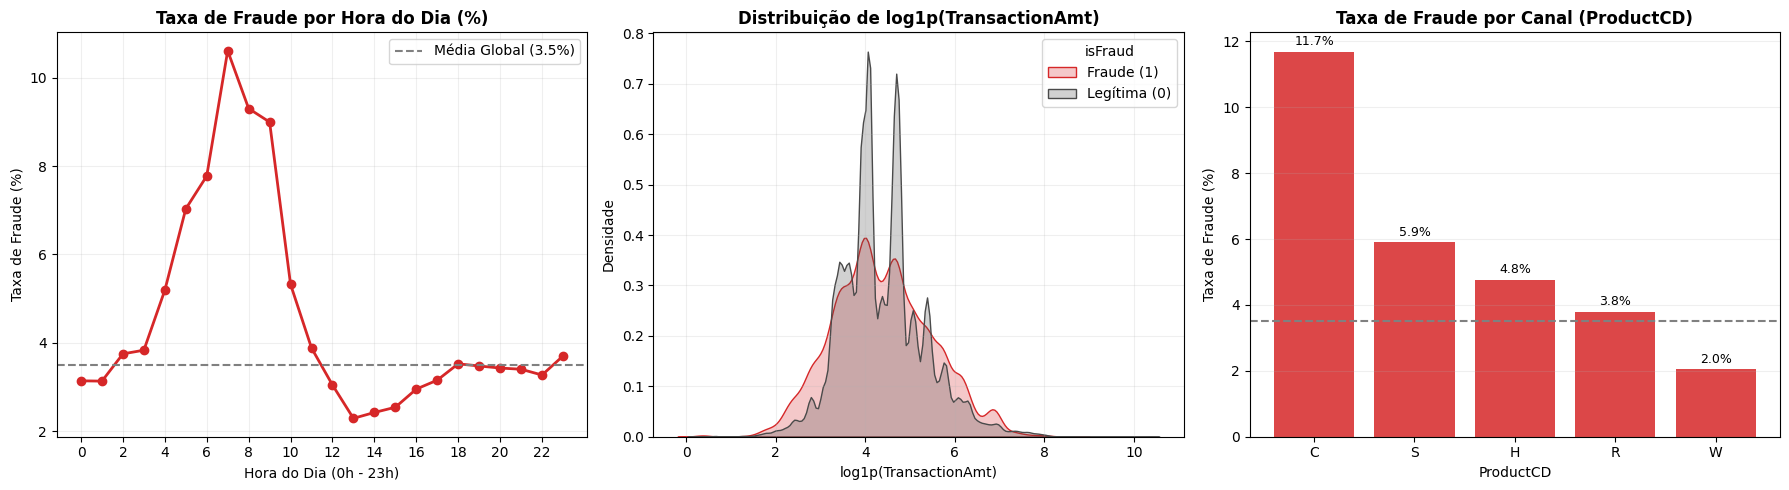

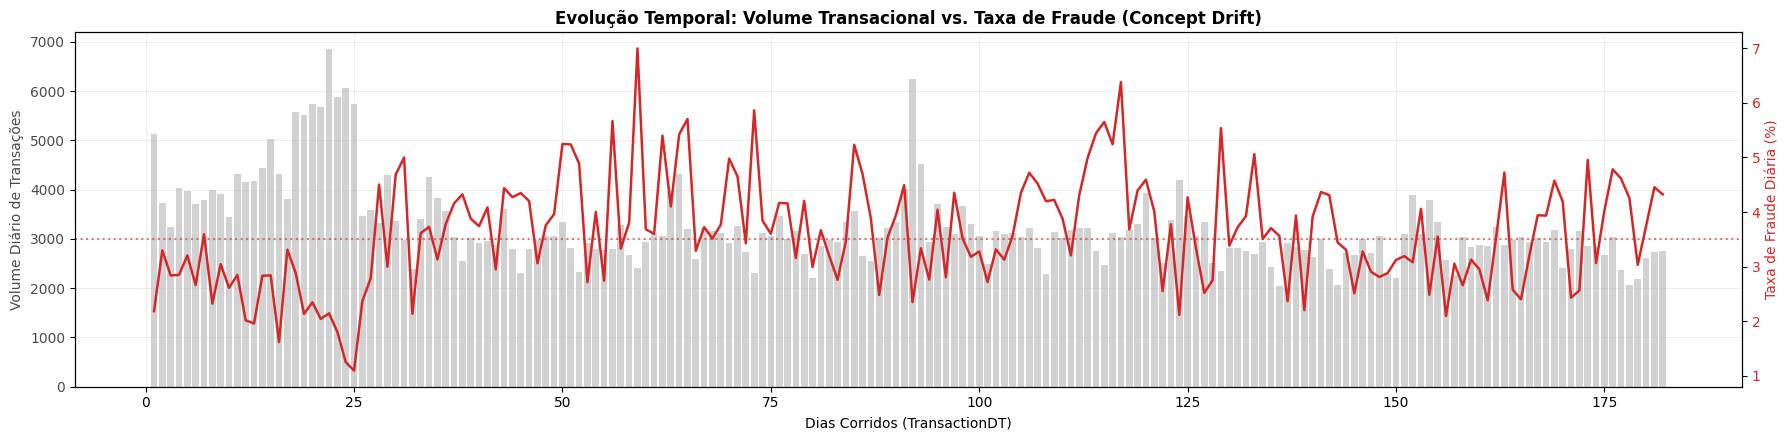

In [23]:
# Garante a coluna de dias corridos a partir de TransactionDT
df_train_tr['Transaction_Day'] = (df_train_tr['TransactionDT'] // (3600 * 24)).astype(int)

# ==============================================================================
# BLOCO A: PAINEL BIVARIADO (HORA, VALOR E CANAL DE PRODUTO)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Taxa de Fraude por Hora do Dia
hora_stats = df_train_tr.groupby('Transaction_Hour')['isFraud'].mean() * 100
axes[0].plot(hora_stats.index, hora_stats.values, marker='o', color='#d62728', linewidth=2)
axes[0].axhline(df_train_tr['isFraud'].mean() * 100, color='gray', linestyle='--', label='Média Global (3.5%)')
axes[0].set_title('Taxa de Fraude por Hora do Dia (%)', fontweight='bold')
axes[0].set_xlabel('Hora do Dia (0h - 23h)')
axes[0].set_ylabel('Taxa de Fraude (%)')
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend()
axes[0].grid(alpha=0.2)

# 2. Distribuição de Valor (Log) por Classe
sns.kdeplot(
    data=df_train_tr, x=np.log1p(df_train_tr['TransactionAmt']),
    hue='isFraud', common_norm=False, fill=True,
    palette={0: '#4a4a4a', 1: '#d62728'}, ax=axes[1]
)
axes[1].set_title('Distribuição de log1p(TransactionAmt)', fontweight='bold')
axes[1].set_xlabel('log1p(TransactionAmt)')
axes[1].set_ylabel('Densidade')
axes[1].legend(title='isFraud', labels=['Fraude (1)', 'Legítima (0)'])
axes[1].grid(alpha=0.2)

# 3. Taxa de Fraude por ProductCD
prod_stats = (df_train_tr.groupby('ProductCD')['isFraud'].mean() * 100).sort_values(ascending=False)
bars = axes[2].bar(prod_stats.index, prod_stats.values, color='#d62728', alpha=0.85)
axes[2].axhline(df_train_tr['isFraud'].mean() * 100, color='gray', linestyle='--')
axes[2].set_title('Taxa de Fraude por Canal (ProductCD)', fontweight='bold')
axes[2].set_xlabel('ProductCD')
axes[2].set_ylabel('Taxa de Fraude (%)')
for bar in bars:
    h = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width()/2, h + 0.2, f'{h:.1f}%', ha='center', fontsize=9)
axes[2].grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.show()

# ==============================================================================
# BLOCO B: EVOLUÇÃO TEMPORAL E CONCEPT DRIFT (DIAS CORRIDOS)
# ==============================================================================
evolucao_dia = df_train_tr.groupby('Transaction_Day')['isFraud'].agg(
    volume='count',
    taxa_fraude=lambda x: x.mean() * 100
).reset_index()

fig, ax1 = plt.subplots(figsize=(18, 4.5))

ax1.bar(evolucao_dia['Transaction_Day'], evolucao_dia['volume'], color='#7f7f7f', alpha=0.35, label='Volume de Transações')
ax1.set_xlabel('Dias Corridos (TransactionDT)')
ax1.set_ylabel('Volume Diário de Transações', color='#4a4a4a')
ax1.tick_params(axis='y', labelcolor='#4a4a4a')

ax2 = ax1.twinx()
ax2.plot(evolucao_dia['Transaction_Day'], evolucao_dia['taxa_fraude'], color='#d62728', linewidth=1.8, label='Taxa de Fraude (%)')
ax2.axhline(df_train_tr['isFraud'].mean() * 100, color='#d62728', linestyle=':', alpha=0.6)
ax2.set_ylabel('Taxa de Fraude Diária (%)', color='#d62728')
ax2.tick_params(axis='y', labelcolor='#d62728')

plt.title('Evolução Temporal: Volume Transacional vs. Taxa de Fraude (Concept Drift)', fontweight='bold')
ax1.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Remove coluna auxiliar de dia caso não queira levá-la adiante
df_train_tr.drop(columns=['Transaction_Day'], inplace=True, errors='ignore')

---
## 5.0 Raio-X e Feature Engineering: Identidade (`df_train_id`)

Compreendido como a fraude opera nas transações, passamos a investigar **quem é o agente e qual dispositivo realiza a transação** através da base `df_train_id`:
1. **5.1** — Contagem de Colunas, Análise de Nulos e Ranking das Variáveis Mais Vazias
2. **5.2** — Remoção do Bloco Inútil (> 90% nulos) e Criação das Flags (`id_null_count`, `has_advanced_network_check`)
3. **5.3** — Análise de Cardinalidade e Distribuições com Valores Únicos $\le 5$
4. **5.4** — Feature Engineering de Identidade (Segurança, Dispositivo, Resolução de Tela, Navegador e Fabricante)

### 5.1 — Análise de Nulos e Ranking das Variáveis Mais Vazias

In [24]:
# Contagem de colunas numéricas e categóricas em df_train_id
resumo_tipos_id = analisar_tipos_colunas(df_train_id, nome_df="df_train_id")

--- Contagem de Colunas por Tipo (df_train_id) ---
  Colunas numéricas inteiras : 1
  Colunas numéricas float    : 23
  Total de colunas numéricas : 24
  Colunas categóricas        : 17
  Total geral de colunas     : 41


In [25]:
# Análise de valores nulos por variável e por faixas de 5%
df_nulos_id = analisar_valores_nulos(df_train_id, plotar=False, top_n=15)
display(df_nulos_id.head(10))

analise_bins_id = analisar_nulos_por_faixa(df_train_id, n_faixas=20)
display(analise_bins_id[analise_bins_id["qtd_colunas"] > 0])

,Total Nulos,Percentual (%),Tipo de Dado
id_24,139486,96.71,float64
id_25,139101,96.44,float64
id_07,139078,96.43,float64
id_08,139078,96.43,float64
id_21,139074,96.42,float64
id_26,139070,96.42,float64
id_22,139064,96.42,float64
id_27,139064,96.42,object
id_23,139064,96.42,object
id_18,99120,68.72,float64


,faixa_nulos,qtd_colunas,exemplos,pct_do_total_colunas
0,"(-0.001, 5.0]",17,"TransactionID, id_01, id_02",41.46
1,"(5.0, 10.0]",2,"id_05, id_06",4.88
2,"(10.0, 15.0]",2,"id_13, id_16",4.88
3,"(15.0, 20.0]",1,DeviceInfo,2.44
8,"(40.0, 45.0]",1,id_14,2.44
9,"(45.0, 50.0]",6,"id_09, id_10, id_30",14.63
10,"(50.0, 55.0]",2,"id_03, id_04",4.88
13,"(65.0, 70.0]",1,id_18,2.44
19,"(95.0, 100.0]",9,"id_07, id_08, id_21",21.95


### 5.2 — Remoção do Bloco Esparso (> 90% Nulos) e Criação de Flags

In [26]:
# Tratando os nulos removendo os de > 90% e criando uma FLAG com numero de valores nulos

# Hipótese: Muitos valores nulos indicam maior probabilidade de fraude

# 1. Cria a meta-feature de contagem de nulos na identidade
df_train_id['id_null_count'] = df_train_id.isnull().sum(axis=1)

# 2. Sintetiza o bloco esparso (id_07, id_08, id_21 a id_27) em uma flag única
if 'id_23' in df_train_id.columns:
    df_train_id['has_advanced_network_check'] = df_train_id['id_23'].notnull().astype('int8')

# 3. Lista de colunas esparsas para descarte definitivo (>90% de nulos em df_id)
cols_to_drop = ['id_07', 'id_08', 'id_21', 'id_22', 'id_23', 'id_24', 'id_25', 'id_26', 'id_27']
df_train_id = df_train_id.drop(columns=cols_to_drop, errors='ignore')

print(f"Colunas restantes em df_train_id:{df_train_id.shape[1]}")

Colunas restantes em df_train_id:34


### 5.3 — Análise de Cardinalidade e Valores Únicos ≤ 5

In [27]:
# Valores únicos por coluna em df_train_id
df_unicos_id = analisar_valores_unicos(df_train_id, top_n=20)

,coluna,valores_unicos
0,id_12,2
1,has_advanced_network_check,2
2,id_38,3
3,id_16,3
4,DeviceType,3
5,id_35,3
6,id_29,3
7,id_37,3
8,id_36,3
9,id_28,3


>
> **Veja que é interessante analisar o que tem de valor único nas colunas com cardinalidade até 5**
>

In [28]:
# Distribuição das colunas com até 5 valores únicos em df_train_id
colunas_baixa_card_id = analisar_baixa_cardinalidade(df_train_id, df_unicos=df_unicos_id, max_unicos=5)

Total de colunas com cardinalidade <= 5: 13

--- Distribuição da coluna: id_12 ---
id_12
NotFound    85.3
Found       14.7

--- Distribuição da coluna: has_advanced_network_check ---
has_advanced_network_check
0    96.42
1     3.58

--- Distribuição da coluna: id_38 ---
id_38
F      51.25
T      46.50
NaN     2.25

--- Distribuição da coluna: id_16 ---
id_16
Found       45.98
NotFound    43.69
NaN         10.33

--- Distribuição da coluna: DeviceType ---
DeviceType
desktop    59.05
mobile     38.58
NaN         2.37

--- Distribuição da coluna: id_35 ---
id_35
T      53.95
F      43.80
NaN     2.25

--- Distribuição da coluna: id_29 ---
id_29
Found       51.95
NotFound    45.80
NaN          2.26

--- Distribuição da coluna: id_37 ---
id_37
T      76.58
F      21.17
NaN     2.25

--- Distribuição da coluna: id_36 ---
id_36
F      92.95
T       4.80
NaN     2.25

--- Distribuição da coluna: id_28 ---
id_28
Found    52.85
New      44.89
NaN       2.26

--- Distribuição da coluna: id_15 ---

### 5.4 — Feature Engineering: Identidade (`df_train_id`)

In [29]:
# 1. Extração Numérica Ordinal (id_34)
# Converte texto como 'match_status:2' para o número 2.0
df_train_id['id_34_score'] = df_train_id['id_34'].str.split(':').str[1].astype(float)

# 2. Assinatura e Contagem de Flags de Segurança (id_35 a id_38)
flags_seguranca = ['id_35', 'id_36', 'id_37', 'id_38']

# Concatena as aprovações para capturar perfis (ex: "T_F_T_F")
df_train_id['assinatura_seguranca'] = (
    df_train_id['id_35'].astype(str) + '_' +
    df_train_id['id_36'].astype(str) + '_' +
    df_train_id['id_37'].astype(str) + '_' +
    df_train_id['id_38'].astype(str)
)

# Conta o total de validações positivas do dispositivo
df_train_id['contagem_seguranca'] = (df_train_id[flags_seguranca] == 'T').sum(axis=1)

# 3. Cruzamento de Histórico e Confiabilidade (id_28 e id_29)
# Combina o histórico do Dispositivo (id_28) com o do IP da rede (id_29)
# Exemplo de anomalia forte: "New_NotFound" (Novo + IP Desconhecido)
df_train_id['device_ip_consistency'] = (
    df_train_id['id_28'].fillna('Miss') + '_' + df_train_id['id_29'].fillna('Miss')
)

# 4. Flag de Dispositivo Atípico/Bots (id_32 - Profundidade de Cores)
# 1 = Monitores reais/orgânicos (24 ou 32 bits)
# 0 = Telas atípicas ou navegadores headless (16, 0)
# -1 = Informação ausente
df_train_id['is_standard_display'] = df_train_id['id_32'].map(
    lambda x: 1 if x in [24.0, 32.0] else (0 if pd.notnull(x) else -1)
).astype('int8')

# 5. Mapeamento Numérico Direto para Modelagem (Variáveis Ordinais/Binárias)
# Transforma as strings originais em proxies numéricos mantendo o NaN intacto
mapa_ordinal = {
    'id_12': {'NotFound': 0, 'Found': 1},
    'id_15': {'Unknown': 0, 'New': 1, 'Found': 2}, 
    'id_16': {'NotFound': 0, 'Found': 1},
    'id_28': {'New': 0, 'Found': 1},
    'id_29': {'NotFound': 0, 'Found': 1},
    'id_35': {'F': 0, 'T': 1},
    'id_36': {'F': 0, 'T': 1},
    'id_37': {'F': 0, 'T': 1},
    'id_38': {'F': 0, 'T': 1},
    'DeviceType': {'desktop': 0, 'mobile': 1}
}

for col, mapping in mapa_ordinal.items():
    if col in df_train_id.columns:
        df_train_id[f'{col}_num'] = df_train_id[col].map(mapping)

# 6. Limpeza de Navegadores (id_31)
# Extrai apenas a primeira palavra (chrome, safari, edge, firefox, ie)
df_train_id['browser_family'] = df_train_id['id_31'].str.split(' ').str[0]
df_train_id['browser_family'] = df_train_id['browser_family'].str.lower().replace({
    'samsung': 'samsung', 'mobile': 'safari', 'google': 'chrome'
})

# 7. Extração Matemática da Resolução (id_33)
# Transforma "1920x1080" na área total de pixels
df_train_id['screen_width'] = df_train_id['id_33'].str.split('x').str[0].astype(float)
df_train_id['screen_height'] = df_train_id['id_33'].str.split('x').str[1].astype(float)
df_train_id['screen_area'] = df_train_id['screen_width'] * df_train_id['screen_height']

# 8. Padronização de Fabricantes (DeviceInfo)
# Isola as principais fabricantes para reduzir cardinalidade
df_train_id['device_brand'] = 'Other'
df_train_id.loc[df_train_id['DeviceInfo'].str.contains('SM-|SAMSUNG', na=False, case=False), 'device_brand'] = 'Samsung'
df_train_id.loc[df_train_id['DeviceInfo'].str.contains('iOS|Mac|Apple', na=False, case=False), 'device_brand'] = 'Apple'
df_train_id.loc[df_train_id['DeviceInfo'].str.contains('Windows', na=False, case=False), 'device_brand'] = 'Windows'
df_train_id.loc[df_train_id['DeviceInfo'].str.contains('Moto|XT', na=False, case=False), 'device_brand'] = 'Motorola'
df_train_id.loc[df_train_id['DeviceInfo'].str.contains('LG-', na=False, case=False), 'device_brand'] = 'LG'
df_train_id.loc[df_train_id['DeviceInfo'].str.contains('Huawei|ALE-|HUAWEI', na=False, case=False), 'device_brand'] = 'Huawei'

print(f"Feature Engineering concluída. Shape atual de df_train_id: {df_train_id.shape}")

Feature Engineering concluída. Shape atual de df_train_id: (144233, 54)


In [30]:
# Amostra das colunas categóricas após Feature Engineering
df_train_id_cat = df_train_id.select_dtypes(include=["object"]).copy()
df_train_id_cat.head(20)

,id_12,id_15,id_16,id_28,id_29,id_30,id_31,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo,assinatura_seguranca,device_ip_consistency,browser_family,device_brand
0,NotFound,New,NotFound,New,NotFound,Android 7.0,samsung browser 6.2,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M,T_F_T_T,New_NotFound,samsung,Samsung
1,NotFound,New,NotFound,New,NotFound,iOS 11.1.2,mobile safari 11.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device,T_F_F_T,New_NotFound,safari,Apple
2,NotFound,Found,Found,Found,Found,NaN,chrome 62.0,NaN,NaN,F,F,T,T,desktop,Windows,F_F_T_T,Found_Found,chrome,Windows
3,NotFound,New,NotFound,New,NotFound,NaN,chrome 62.0,NaN,NaN,F,F,T,T,desktop,NaN,F_F_T_T,New_NotFound,chrome,Other
4,NotFound,Found,Found,Found,Found,Mac OS X 10_11_6,chrome 62.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS,T_F_T_T,Found_Found,chrome,Apple
5,NotFound,Found,Found,Found,Found,Windows 10,chrome 62.0,1366x768,match_status:2,T,F,T,T,desktop,Windows,T_F_T_T,Found_Found,chrome,Windows
6,NotFound,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nan_nan_nan_nan,Miss_Miss,NaN,Other
7,Found,Found,Found,Found,Found,Android,chrome 62.0,1920x1080,match_status:2,T,F,T,T,mobile,NaN,T_F_T_T,Found_Found,chrome,Other
8,NotFound,Found,Found,Found,Found,NaN,chrome 62.0,NaN,NaN,F,F,T,T,desktop,Windows,F_F_T_T,Found_Found,chrome,Windows
9,NotFound,New,NotFound,New,NotFound,NaN,chrome 62.0,NaN,NaN,F,F,T,T,desktop,Windows,F_F_T_T,New_NotFound,chrome,Windows


In [31]:
df_train_id.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144233 entries, 0 to 144232
Data columns (total 54 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   TransactionID               144233 non-null  int64  
 1   id_01                       144233 non-null  float64
 2   id_02                       140872 non-null  float64
 3   id_03                       66324 non-null   float64
 4   id_04                       66324 non-null   float64
 5   id_05                       136865 non-null  float64
 6   id_06                       136865 non-null  float64
 7   id_09                       74926 non-null   float64
 8   id_10                       74926 non-null   float64
 9   id_11                       140978 non-null  float64
 10  id_12                       144233 non-null  object 
 11  id_13                       127320 non-null  float64
 12  id_14                       80044 non-null   float64
 13  id_15         

---
## 6.0 Unificação (Merge) e Saneamento Financeiro

Consolidação das tabelas tratadas (`df_train_tr` + `df_train_id`) e enriquecimento estatístico global:
1. **6.1** — Otimização de Memória (`safe_downcast`) nas bases isoladas e `left join` via `TransactionID`
2. **6.2** — Engenharia Pós-Merge (Razão `TransactionAmt_to_mean_card1` e Frequency Encoding para alta cardinalidade)
3. **6.3** — Análise e Transformação de Caudas Longas (`np.log1p` para corrigir assimetria $> 1.0$)

### 6.1 — Otimização de Memória (`safe_downcast`) e Merge (`df_train`)

In [32]:
# Descarta as colunas textuais brutas de identidade que já foram extraídas matematicamente para economizar RAM
df_train_id.drop(columns=["id_31", "id_33", "DeviceInfo"], inplace=True, errors="ignore")

# Aplica o downcast seguro via utils.py nas duas tabelas isoladas
df_train_tr = safe_downcast(df_train_tr)
df_train_id = safe_downcast(df_train_id)

# Realiza o Merge (left join) mantendo todas as linhas de transação
df_train = df_train_tr.merge(df_train_id, on="TransactionID", how="left")
print(f"Shape consolidado de df_train: {df_train.shape}")

Downcast concluído: 1829.8 MB -> 957.4 MB (-47.7%)
Downcast concluído: 54.2 MB -> 35.4 MB (-34.8%)
Shape consolidado de df_train: (590540, 467)


In [33]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 590540 entries, 0 to 590539
Columns: 467 entries, TransactionID to device_brand
dtypes: category(2), float32(413), float64(5), int16(2), int32(1), int64(1), int8(10), object(33)
memory usage: 1.1+ GB


In [34]:
# Quantidade de colunas numéricas e categóricas após o merge
resumo_tipos_final = analisar_tipos_colunas(df_train, nome_df="df_train (Pós-Merge)")
display(resumo_tipos_final)

--- Contagem de Colunas por Tipo (df_train (Pós-Merge)) ---
  Colunas numéricas inteiras : 14
  Colunas numéricas float    : 418
  Total de colunas numéricas : 432
  Colunas categóricas        : 35
  Total geral de colunas     : 467


,Grupo de Tipo,Quantidade
0,Numéricas Inteiras,14
1,Numéricas Float,418
2,Categóricas (object/category),35
3,Total,467


### 6.2 — Engenharia Pós-Merge: Razão por Cartão e Frequency Encoding

In [35]:
# 1. Razão do Valor da Transação pela Média do próprio Cartão (card1)
# Captura desvios bruscos de gasto em relação ao comportamento histórico daquele cartão específico
card1_mean_amt = df_train.groupby('card1')['TransactionAmt'].transform('mean')
df_train['TransactionAmt_to_mean_card1'] = (
    df_train['TransactionAmt'] / (card1_mean_amt + 1e-5)
).astype('float32')

# 2. Frequency Encoding nos identificadores de alta cardinalidade
# Quantas vezes esse cartão/endereço/domínio aparece na base? Ataques de botnet repetem identificadores em massa
cols_freq = ['card1', 'card2', 'addr1', 'P_emaildomain']
for col in cols_freq:
    if col in df_train.columns:
        freq = df_train[col].value_counts(dropna=False)
        df_train[f'{col}_freq'] = df_train[col].map(freq).astype('float32')

print("Engenharia pós-merge concluída: TransactionAmt_to_mean_card1 e Frequency Encoding (card1, card2, addr1, P_emaildomain).")

Engenharia pós-merge concluída: TransactionAmt_to_mean_card1 e Frequency Encoding (card1, card2, addr1, P_emaildomain).


### 6.3 — Análise e Transformação de Caudas Longas (`np.log1p`)

Total de colunas avaliadas      : 312
Colunas com Skew > 1.0 (log1p): 279
Ignoradas por valores negativos : 7


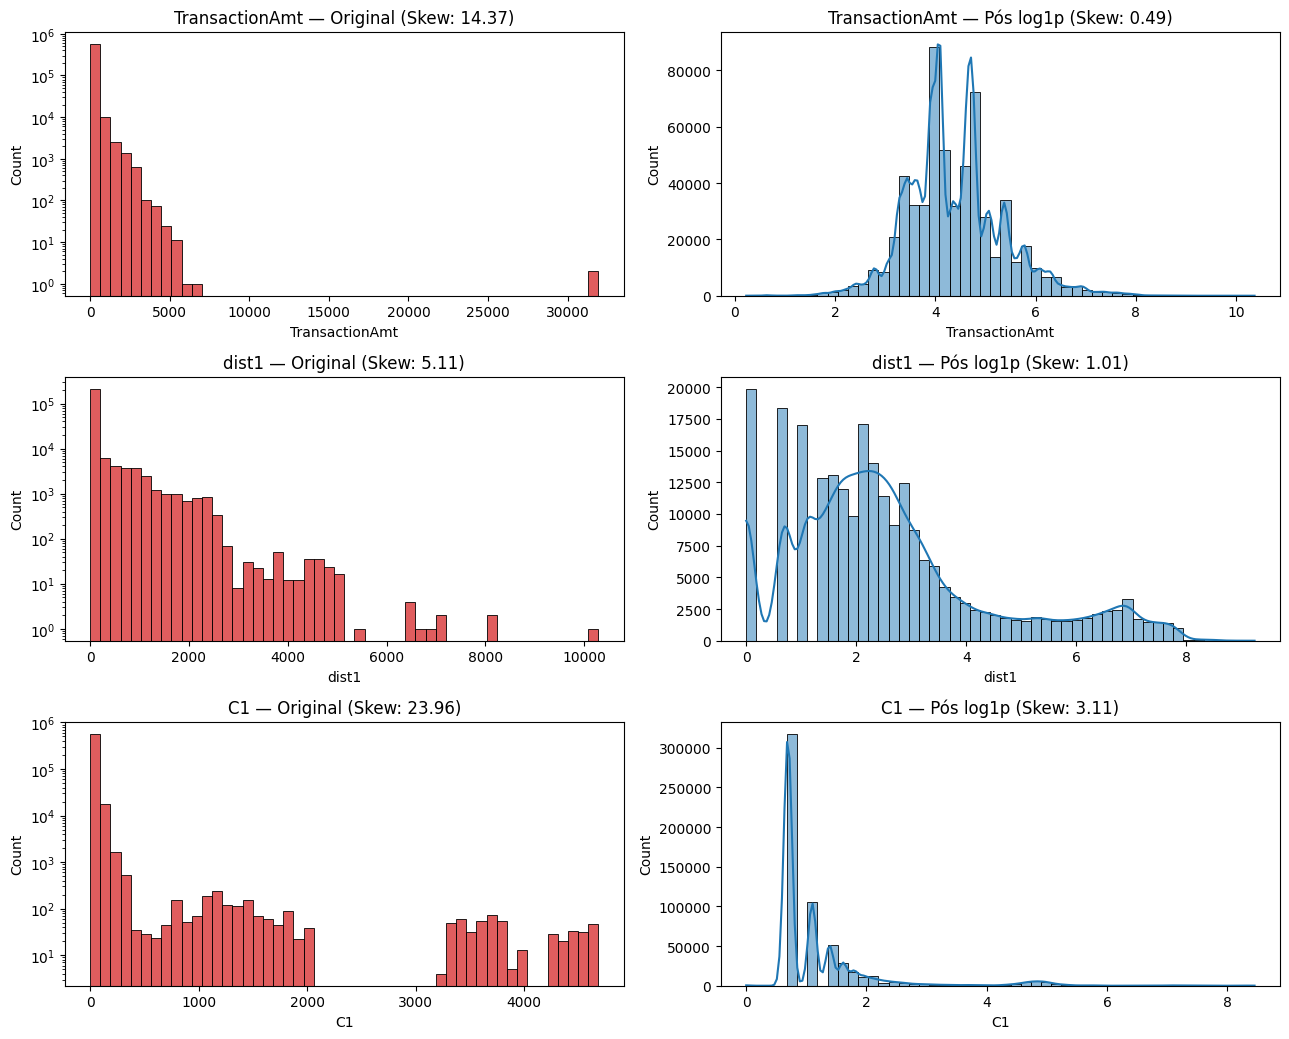

,Feature,Min,Max,Skew_Antes,Skew_Depois,Status
0,V311,0.0,55125.0,323.83,6.12,Transformada (log1p)
1,V129,0.0,55125.0,240.27,4.26,Transformada (log1p)
2,V309,0.0,55125.0,224.88,3.48,Transformada (log1p)
3,V206,0.0,55125.0,207.88,4.78,Transformada (log1p)
4,V319,0.0,104060.0,181.83,4.73,Transformada (log1p)
5,V269,0.0,55125.0,177.84,8.56,Transformada (log1p)
6,V266,0.0,55125.0,175.96,3.67,Transformada (log1p)
7,V334,0.0,55125.0,168.47,4.84,Transformada (log1p)
8,V135,0.0,90750.0,144.88,4.81,Transformada (log1p)
9,V321,0.0,104060.0,123.56,4.20,Transformada (log1p)


In [36]:
# Diagnostica assimetria (skewness > 1.0) nas numéricas contínuas/discretas e aplica np.log1p onde min >= 0
df_train, df_skew_report = analisar_e_transformar_caudas_longas(
    df_train,
    limiar_skew=1.0,
    min_unicos=10,
    substituir_original=True,
    plotar_top=3
)

display(df_skew_report.head(20))

---
## 7.0 Seleção Multivariada e Exportação (O Funil do `df_master`)

Etapa final de seleção estatística e redução de dimensionalidade para produzir o dataset enxuto (`df_master`):
1. **7.1** — Cálculo do Information Value (IV) com régua calibrada para Detecção de Fraude
2. **7.2** — Diagnóstico de Correlação de Pares e O Funil de Saneamento (Descarte de texto bruto, corte de ruído $\text{IV} < 0.02$ e poda de redundância $|r| > 0.75$ protegendo maior IV e menor taxa de nulo)
3. **7.3** — Diagnóstico Final de VIF nas variáveis sobreviventes (amostra de 20.000 linhas)
4. **7.4** — Exportação final (`df_master.parquet` e dicionário `features_metadata.json`)

### 7.1 — Cálculo do Information Value (IV) das Features

In [37]:
# Calculando o Information Value (IV) de todas as variáveis em relação ao target isFraud
df_iv = calcular_iv_dataset(df_train, target_col="isFraud", bins=10)

print("Resumo por faixa de Poder Preditivo:")
display(df_iv["Diagnóstico"].value_counts().to_frame("Quantidade de Features"))

print("\nTop 30 Features com maior Information Value:")
display(df_iv.head(30))

Resumo por faixa de Poder Preditivo:


,Quantidade de Features
Diagnóstico,
Poder Forte,179
Poder Fraco,106
Poder Médio,99
Sem Poder Preditivo,81
Poder Altíssimo (Padrão Fraude),5



Top 30 Features com maior Information Value:


,Feature,Information_Value,Diagnóstico
0,V258,0.9376,Poder Altíssimo (Padrão Fraude)
1,V257,0.9157,Poder Altíssimo (Padrão Fraude)
2,V199,0.8590,Poder Altíssimo (Padrão Fraude)
3,V201,0.8146,Poder Altíssimo (Padrão Fraude)
4,V189,0.8134,Poder Altíssimo (Padrão Fraude)
5,V200,0.7982,Poder Forte
6,V188,0.7893,Poder Forte
7,V246,0.7865,Poder Forte
8,V187,0.7864,Poder Forte
9,V190,0.7819,Poder Forte


### 7.2 — Análise de Correlação de Pares e O Funil de Saneamento (`df_master`)

In [38]:
# Diagnóstico dos pares de features com correlação > 0.70 (ordenados pelo maior IV à esquerda)
df_pares_colineares = analise_correlacao_pares(df_train, target_col="isFraud", limite=0.70)
display(df_pares_colineares.head(30))

--- Pares com Correlação > 0.7 (Total: 2676 pares) ---
is_V14_zero (IV: 0.0002) & V14 (IV: 0.0002) | Corr: 1.000
D9 (IV: 0.1266) & Transaction_Hour (IV: 0.0594) | Corr: 1.000
D4 (IV: 0.2654) & D12 (IV: 0.1494) | Corr: 1.000
D5 (IV: 0.8816) & D7 (IV: 0.3690) | Corr: 0.998
V18 (IV: 0.0710) & V17 (IV: 0.0643) | Corr: 0.998
V150 (IV: 0.2253) & V151 (IV: 0.2245) | Corr: 0.997
id_35_num (IV: 0.2879) & is_standard_display (IV: 0.2710) | Corr: 0.996
V154 (IV: 0.9994) & V153 (IV: 0.9112) | Corr: 0.996
V15 (IV: 0.6012) & V16 (IV: 0.0143) | Corr: 0.996
V31 (IV: 0.5513) & V32 (IV: 0.0139) | Corr: 0.995
V180 (IV: 0.0416) & V182 (IV: 0.0416) | Corr: 0.994
V251 (IV: 0.3033) & V250 (IV: 0.2484) | Corr: 0.994
V256 (IV: 0.2518) & V255 (IV: 0.2300) | Corr: 0.992
V156 (IV: 1.1861) & V155 (IV: 1.0080) | Corr: 0.991
V155 (IV: 1.0080) & V148 (IV: 0.9740) | Corr: 0.991
V149 (IV: 1.1573) & V148 (IV: 0.9740) | Corr: 0.991
V156 (IV: 1.1861) & V149 (IV: 1.1573) | Corr: 0.991
V270 (IV: 0.0000) & V272 (IV: 0.0000) 

,Feature_Manter,IV_Manter,Feature_Descartar,IV_Descartar,Correlacao
0,is_V14_zero,0.0002,V14,0.0002,1.0000
1,D9,0.1266,Transaction_Hour,0.0594,1.0000
2,D4,0.2654,D12,0.1494,1.0000
3,D5,0.8816,D7,0.3690,0.9978
4,V18,0.0710,V17,0.0643,0.9977
5,V150,0.2253,V151,0.2245,0.9970
6,id_35_num,0.2879,is_standard_display,0.2710,0.9964
7,V154,0.9994,V153,0.9112,0.9962
8,V15,0.6012,V16,0.0143,0.9961
9,V31,0.5513,V32,0.0139,0.9946


In [39]:
# ==============================================================================
# CONFIGURAÇÃO INICIAL: Dicionário de IVs e Proteção de Colunas
# ==============================================================================
iv_dict = dict(zip(df_iv['Feature'], df_iv['Information_Value']))
cols_freq = ['card1', 'card2', 'addr1', 'P_emaildomain']
for new_c in ['TransactionAmt_to_mean_card1'] + [f'{c}_freq' for c in cols_freq]:
    if new_c in df_train.columns and new_c not in iv_dict:
        iv_dict[new_c] = 0.25

cols_protegidas = ['TransactionID', 'isFraud', 'TransactionDT']

# ==============================================================================
# PASSO 1: Descarte de colunas textuais brutas (já convertidas em _num, _limpo, _freq)
# ==============================================================================
cols_brutas_substituidas = [
    'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9',
    'card6', 'id_12', 'id_15', 'id_16', 'id_28', 'id_29',
    'id_31', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38',
    'DeviceType', 'DeviceInfo', 'is_V14_zero', 'V14'
]
cols_drop_duplicadas = [c for c in cols_brutas_substituidas if c in df_train.columns]

# ==============================================================================
# PASSO 2: Descarte de Ruído Estatístico (IV < 0.02)
# Nota: Mantemos as features com IV > 0.50 pois em fraude são sinais reais fortes!
# ==============================================================================
LIMIAR_IV_MINIMO = 0.02

cols_drop_baixo_iv = [
    col for col, iv in iv_dict.items()
    if iv < LIMIAR_IV_MINIMO and col in df_train.columns and col not in cols_protegidas
]

print(f"1. Colunas brutas já convertidas para remover: {len(cols_drop_duplicadas)}")
print(f"2. Colunas sem poder preditivo (IV < {LIMIAR_IV_MINIMO}) para remover: {len(cols_drop_baixo_iv)}")

df_temp = df_train.drop(columns=list(set(cols_drop_duplicadas + cols_drop_baixo_iv)))

# ==============================================================================
# PASSO 3: Poda por Matriz de Correlação (> 0.75) protegendo Maior IV + Trava de Nulos
# ==============================================================================
LIMIAR_CORR = 0.75
TOLERANCIA_NULOS = 0.20

num_cols_sobreviventes = [
    c for c in df_temp.select_dtypes(include=[np.number]).columns
    if c not in cols_protegidas
]

num_cols_ordenadas = sorted(
    num_cols_sobreviventes,
    key=lambda x: iv_dict.get(x, 0.0),
    reverse=True
)

print("\nCalculando matriz de correlação das variáveis sobreviventes...")
corr_matrix = df_temp[num_cols_ordenadas].corr().abs()
null_series = df_temp[num_cols_ordenadas].isnull().mean()

cols_drop_corr = set()
for i, col_forte in enumerate(num_cols_ordenadas):
    if col_forte in cols_drop_corr:
        continue
    for col_fraca in num_cols_ordenadas[i + 1:]:
        if col_fraca in cols_drop_corr:
            continue
        if corr_matrix.loc[col_forte, col_fraca] > LIMIAR_CORR:
            # Só descarta a de menor IV se a de maior IV não tiver >20% a mais de nulos
            if null_series[col_forte] <= null_series[col_fraca] + TOLERANCIA_NULOS:
                cols_drop_corr.add(col_fraca)

print(f"3. Colunas removidas por Alta Correlação (> {LIMIAR_CORR}) mantendo Maior IV: {len(cols_drop_corr)}")

# ==============================================================================
# PASSO 4: Consolidação e Downcast do df_master
# ==============================================================================
df_master = df_temp.drop(columns=list(cols_drop_corr))
df_master = safe_downcast(df_master)

print("=" * 65)
print("RESUMO DO FUNIL DE SANEAMENTO (df_master):")
print(f" -> Shape Original (df_train) : {df_train.shape}")
print(f" -> Shape Enxuto (df_master)  : {df_master.shape}")
print(f" -> Total de Colunas Removidas: {df_train.shape[1] - df_master.shape[1]}")
print("=" * 65)

1. Colunas brutas já convertidas para remover: 23
2. Colunas sem poder preditivo (IV < 0.02) para remover: 81

Calculando matriz de correlação das variáveis sobreviventes...
3. Colunas removidas por Alta Correlação (> 0.75) mantendo Maior IV: 213
Downcast concluído: 375.1 MB -> 368.3 MB (-1.8%)
RESUMO DO FUNIL DE SANEAMENTO (df_master):
 -> Shape Original (df_train) : (590540, 472)
 -> Shape Enxuto (df_master)  : (590540, 157)
 -> Total de Colunas Removidas: 315


### 7.3 — Diagnóstico Final de VIF nas Sobreviventes (`sample_size=20_000`)

In [40]:
# Diagnóstico de VIF (amostrando 20.000 linhas apenas nas variáveis sobreviventes do df_master)
df_vif = analisar_vif(
    df_master,
    limite=10.0,
    imputar_nulos=True,
    sample_size=20_000,
    random_state=42,
    target_col="isFraud",
)
display(df_vif.head(30))

Amostrando 20,000 de 590,540 linhas para cálculo do VIF (random_state=42)...


/content/utils.py:3732: UserWarning: The design matrix is poorly conditioned (condition number=4.79e+15). VIF calculations may be numerically unstable.
  vif_val = variance_inflation_factor(valores, i)
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: Singu

--- Variáveis com VIF > 10.0 (Total: 7 de 141 variáveis numéricas) ---
  V240: 1000799917193443.50
  V241: 1000799917193443.50
  V168: 23.77
  contagem_seguranca: 20.73
  V171: 17.67
  V264: 11.74
  id_38_num: 11.46


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


,Feature,VIF
0,V240,1.000800e+15
1,V241,1.000800e+15
2,V168,2.377326e+01
3,contagem_seguranca,2.073065e+01
4,V171,1.767103e+01
5,V264,1.173963e+01
6,id_38_num,1.145970e+01
7,V207,9.758192e+00
8,V201,9.614083e+00
9,V97,9.475421e+00


### 7.4 — Exportação Final (`df_master.parquet` e `features_metadata.json`)

In [41]:
from pathlib import Path
import json
# Define o diretório de saída automaticamente (Colab ou ambiente local)
cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
DIR_MASTER = PROJECT_ROOT / "data" / "processed"
DIR_MASTER.mkdir(parents=True, exist_ok=True)

# 1. Remove primeiro a redundância perfeita entre V240 e V241 (mantendo a de maior IV)
if 'V240' in df_master.columns and 'V241' in df_master.columns:
    col_drop_vif = 'V241' if iv_dict.get('V240', 0) >= iv_dict.get('V241', 0) else 'V240'
    df_master.drop(columns=[col_drop_vif], inplace=True)
    print(f"Coluna singular removida: {col_drop_vif}")

# 2. Separa listas de features por tipo APÓS todas as remoções estarem concluídas
cat_features = [c for c in df_master.select_dtypes(include=['object', 'category']).columns if c not in cols_protegidas]
num_features = [c for c in df_master.select_dtypes(include=[np.number]).columns if c not in cols_protegidas]

# 3. Top 50 numéricas mais densas (<30% nulos) e maior IV (sem a soma redundante do bloco id_35..38)
cols_excluir_linear = {'contagem_seguranca'}
linear_features = [
    c for c in sorted(num_features, key=lambda x: iv_dict.get(x, 0), reverse=True)
    if df_master[c].isnull().mean() < 0.30 and c not in cols_excluir_linear
][:50]

# 4. Exporta o df_master finalizado e o dicionário de metadados sincronizado
parquet_path = DIR_MASTER / "df_master.parquet"
metadata_path = DIR_MASTER / "features_metadata.json"

df_master.to_parquet(parquet_path, index=False)

metadata = {
    "all_features": num_features + cat_features,
    "num_features": num_features,
    "cat_features": cat_features,
    "linear_baseline_features": linear_features
}

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print(f"df_master exportado com sucesso em: {parquet_path.resolve()}")
print(f"Shape final: {df_master.shape}")
print(f" -> Numéricas: {len(num_features)} | Categóricas: {len(cat_features)} | Baseline Linear: {len(linear_features)}")

Coluna singular removida: V241
df_master exportado com sucesso em: /content/data/processed/df_master.parquet
Shape final: (590540, 156)
 -> Numéricas: 140 | Categóricas: 13 | Baseline Linear: 50
